# Predicting income with basic machine learning models

I built this notebook to understand how common classification models behave on the Adult Census dataset. The goal is to predict whether a record falls in the `>50K` income class. I also want to know when a better-looking accuracy score actually means better predictions for that less common class.

I start with a model that always predicts the majority class. Then I compare Logistic Regression, a Decision Tree, Bagging, Random Forest, Gradient Boosting, and XGBoost. I use the same validation folds for every model and look at precision, recall, F1, ROC-AUC, and the mistakes in the confusion matrix.

### How the notebook is organized

1. Check the source data and remove predictor rows shared between the development and test files.
2. Explore the development data and decide how to prepare the features.
3. Compare models with stratified cross-validation.
4. Evaluate the fitted models on the supplied test file.
5. Look at errors, feature importance, and limitations.

The files are in the project's `adult` folder. The dataset notes in `adult/adult.names` credit Ronny Kohavi and Barry Becker. Here `>50K` is class **1** and `<=50K` is class **0**. Run the notebook from the project root with Python, pandas, NumPy, matplotlib, scikit-learn, and XGBoost installed. I use random seed **42** throughout.


In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn import __version__ as sklearn_version

SEED = 42

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print(f"Python {sys.version.split()[0]}")
print(f"pandas {pd.__version__}")
print(f"NumPy {np.__version__}")
print(f"scikit-learn {sklearn_version}")


Python 3.11.11
pandas 2.2.3
NumPy 1.26.4
scikit-learn 1.6.1


## 1. Load and check the data

The dataset comes with a development file (`adult/adult.data`) and a separate test file (`adult/adult.test`). I use the first for exploration and model selection and save the second for final evaluation. The test file has a comment at the top and a period after each income label, so I remove those when loading it. A question mark means the category is unknown.

I also check whether the same predictor values appear in both files. I remove exact duplicates and shared predictor rows **only from development**. The test file stays as supplied. The audit below shows how many rows remain, the column types, and where values are missing.


In [2]:
# Give the columns clear names when reading the files.
columns = [
    "age", "work_class", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income"
]
COLUMNS = columns

dev_raw = pd.read_csv(
    "adult/adult.data",
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

holdout = pd.read_csv(
    "adult/adult.test",
    names=columns,
    skiprows=1,
    skipinitialspace=True,
    na_values="?"
)
holdout["income"] = holdout["income"].str.rstrip(".")

# Compare the predictors only. The test labels are not needed here.
FEATURE_COLUMNS = [col for col in columns if col != "income"]
test_features = holdout[FEATURE_COLUMNS].drop_duplicates()

joined = dev_raw.merge(
    test_features,
    on=FEATURE_COLUMNS,
    how="left",
    indicator=True,
    sort=False
)

overlap_count = int(joined["_merge"].eq("both").sum())
development = joined.loc[
    joined["_merge"].eq("left_only"), columns
].drop_duplicates().reset_index(drop=True)

audit = pd.DataFrame({
    "Item": [
        "Development supplied",
        "Test supplied",
        "Overlapping development rows removed",
        "Duplicate development rows supplied",
        "Development rows used",
        "Test rows evaluated"
    ],
    "Count": [
        len(dev_raw),
        len(holdout),
        overlap_count,
        int(dev_raw.duplicated().sum()),
        len(development),
        len(holdout)
    ]
})

print(audit.to_string(index=False))
print("\nData types:\n")
print(development.dtypes.to_string())
print("\nMissing values in development:\n")
print(development.isna().sum().to_string())
print("\nMissing values in holdout:\n")
print(holdout.isna().sum().to_string())

assert development["income"].isin(["<=50K", ">50K"]).all()
assert holdout["income"].isin(["<=50K", ">50K"]).all()


                                Item  Count
                Development supplied  32561
                       Test supplied  16281
Overlapping development rows removed     28
 Duplicate development rows supplied     24
               Development rows used  32511
                 Test rows evaluated  16281

Data types:

age                int64
work_class        object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object

Missing values in development:

age                  0
work_class        1832
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1839
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss     

### Feature dictionary

Here is a quick guide to the columns I use. I wrote their names in `snake_case`; the source notes in `adult/adult.names` sometimes use a different spelling (for example, `workclass`).

| Column | Type | Meaning |
| --- | --- | --- |
| `age` | Numeric | Person's age in years. |
| `work_class` | Categorical | Type of employer or work arrangement, such as private, government, or self-employment. |
| `fnlwgt` | Numeric | Census final weight used to represent people in population estimates; **not the person's income**. |
| `education` | Categorical | Highest recorded education category, such as high school graduate or bachelor's degree. |
| `education_num` | Numeric code | Numeric encoding of `education`. It is dropped before modeling because it repeats the same education information. |
| `marital_status` | Categorical | Recorded marital-status category. |
| `occupation` | Categorical | Type of job or occupation, such as sales or professional specialty. |
| `relationship` | Categorical | Recorded household or family relationship category, such as husband, wife, own child, or not in family. |
| `race` | Categorical | Race category recorded in the original dataset; a sensitive attribute. |
| `sex` | Categorical | Sex category recorded as Female or Male in this dataset; a sensitive attribute. |
| `capital_gain` | Numeric | Recorded capital-gain amount. Many records have zero. |
| `capital_loss` | Numeric | Recorded capital-loss amount. Many records have zero. |
| `hours_per_week` | Numeric | Reported number of hours worked per week. |
| `native_country` | Categorical | Recorded native-country category. |
| `income` | **Target** | Income class: `<=50K` or `>50K`. It is a label, **not an exact income amount**, and is never used as a predictor. |

I use 13 of these columns as predictors. `income` is the answer I am trying to predict, and I drop `education_num` because it repeats `education`. The preprocessing pipeline handles unknown categories marked `?`.


### How I handle missing and repeated rows

The unknown values are in categorical fields such as work class and occupation. I keep those rows and fill each missing category with the most common value **from the training fold**. I use the training-fold median if a numeric field has a missing value. These steps live inside each model pipeline, so validation and test rows never set the imputation values.

I remove repeated development rows because otherwise they would receive extra weight during training. I also remove development rows whose predictor values appear in the test file, even if their income labels differ. This keeps the model from training on a test input, and the overlap check never uses the test labels. I leave the test file unchanged.


## 2. Explore the development data

Before fitting models, I want to see how common each income class is, which values are missing, and whether numeric variables have unusual ranges. I also look at the income rate across a few common categories. These plots use **development data only**; I keep the test file out of these choices. Differences between groups are descriptive and do not show what caused a person's income.


### 2.1 How balanced is the target?

I first plot the number and share of records in each income class. The larger class tells me how much accuracy I could get by always guessing `<=50K`. That gives every real model a useful starting point to beat.


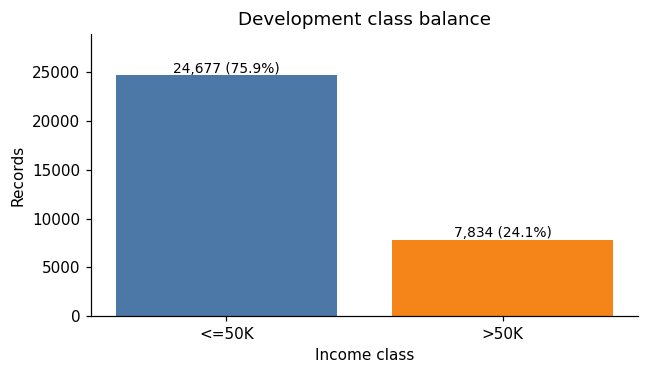

Majority-class accuracy: 0.759
Accuracy alone may hide poor recall for the >50K class.


In [3]:
# Check the balance between the two income classes.
counts = development["income"].value_counts()
counts = counts.reindex(["<=50K", ">50K"])

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(
    counts.index,
    counts.values,
    color=["#4C78A8", "#F58518"]
)

for bar, count in zip(bars, counts):
    percentage = count / len(development)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 250,
        f"{count:,} ({percentage:.1%})",
        ha="center",
        fontsize=9
    )

ax.set(
    title="Development class balance",
    xlabel="Income class",
    ylabel="Records",
    ylim=(0, counts.max() * 1.17)
)

plt.tight_layout()
plt.show()

majority_accuracy = counts.max() / counts.sum()
print(f"Majority-class accuracy: {majority_accuracy:.3f}")
print("Accuracy alone may hide poor recall for the >50K class.")


### 2.2 Where are values missing?

The bars show how many development records have an unknown value in each affected column. I need this check because the source files use `?` rather than an empty cell for many missing categories.


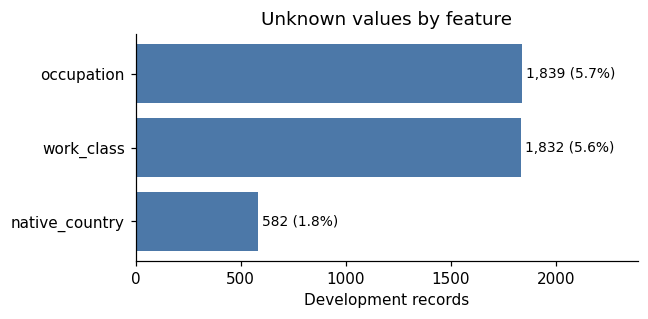

The missing markers are in categorical columns.


In [4]:
# Show which columns have unknown values.
missing = development.isna().sum()
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(missing.index, missing.values, color="#4C78A8")

for row, count in enumerate(missing.values):
    percentage = count / len(development)
    ax.text(
        count + 20,
        row,
        f"{count:,} ({percentage:.1%})",
        va="center",
        fontsize=9
    )

ax.set(
    title="Unknown values by feature",
    xlabel="Development records",
    xlim=(0, missing.max() * 1.3)
)

plt.tight_layout()
plt.show()

print("The missing markers are in categorical columns.")


### 2.3 What do the numeric values look like?

I plot age, hours worked per week, capital gain, and capital loss, then show a few percentiles. I am looking for skew, long tails, and values that deserve a closer look. For example, capital gain and loss have many zeros. The `fnlwgt` field is a census weight, not someone's income.


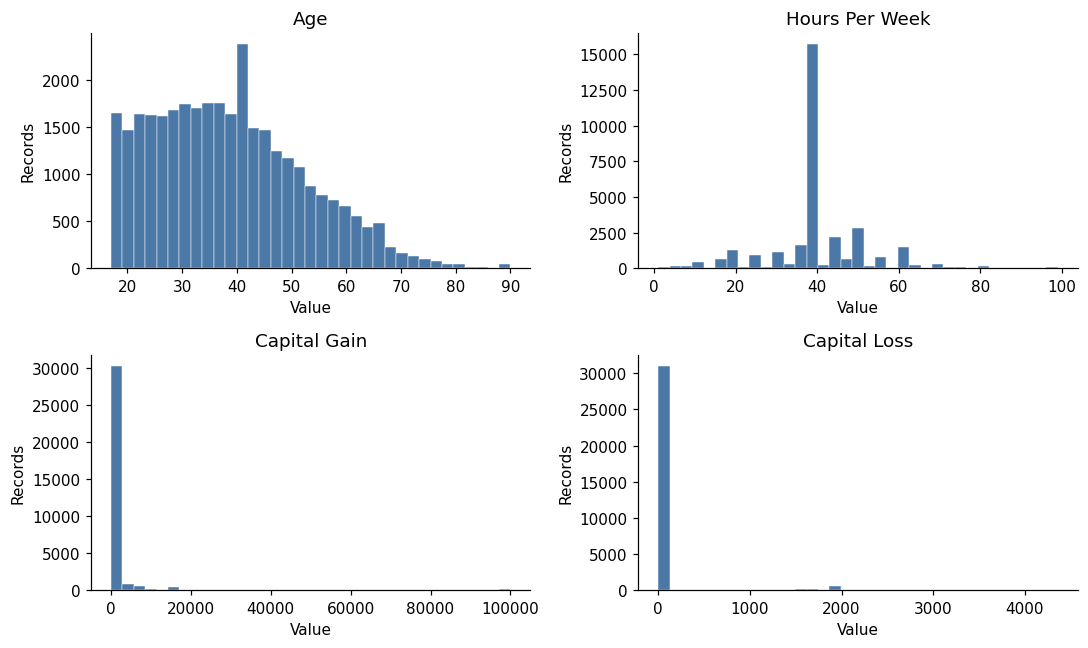

Capital gain and loss have many zeros and long right tails.
Age and hours worked have a wider spread.

Numeric summary:

           age  hours_per_week  capital_gain  capital_loss
count  32511.0         32511.0       32511.0       32511.0
mean      38.6            40.4        1079.3          87.4
std       13.6            12.3        7390.8         403.3
min       17.0             1.0           0.0           0.0
50%       37.0            40.0           0.0           0.0
90%       58.0            55.0           0.0           0.0
99%       74.0            80.0       15024.0        1980.0
max       90.0            99.0       99999.0        4356.0

fnlwgt is a census weight, not a person's income.


In [5]:
# Look at the spread of the main numeric features.
numeric_view = [
    "age",
    "hours_per_week",
    "capital_gain",
    "capital_loss"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for ax, feature in zip(axes.flat, numeric_view):
    ax.hist(
        development[feature],
        bins=35,
        color="#4C78A8",
        edgecolor="white",
        linewidth=0.3
    )
    ax.set(
        title=feature.replace("_", " ").title(),
        xlabel="Value",
        ylabel="Records"
    )

plt.tight_layout()
plt.show()

print("Capital gain and loss have many zeros and long right tails.")
print("Age and hours worked have a wider spread.")
print("\nNumeric summary:\n")
print(
    development[numeric_view]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(1)
    .to_string()
)
print("\nfnlwgt is a census weight, not a person's income.")


### 2.4 How do common categories compare?

These plots show the observed `>50K` rate for common education, occupation, and work-class categories. I include the number of records beside each bar. A striking rate from a small group is less reliable than a similar rate from thousands of records, and none of these comparisons establishes cause.


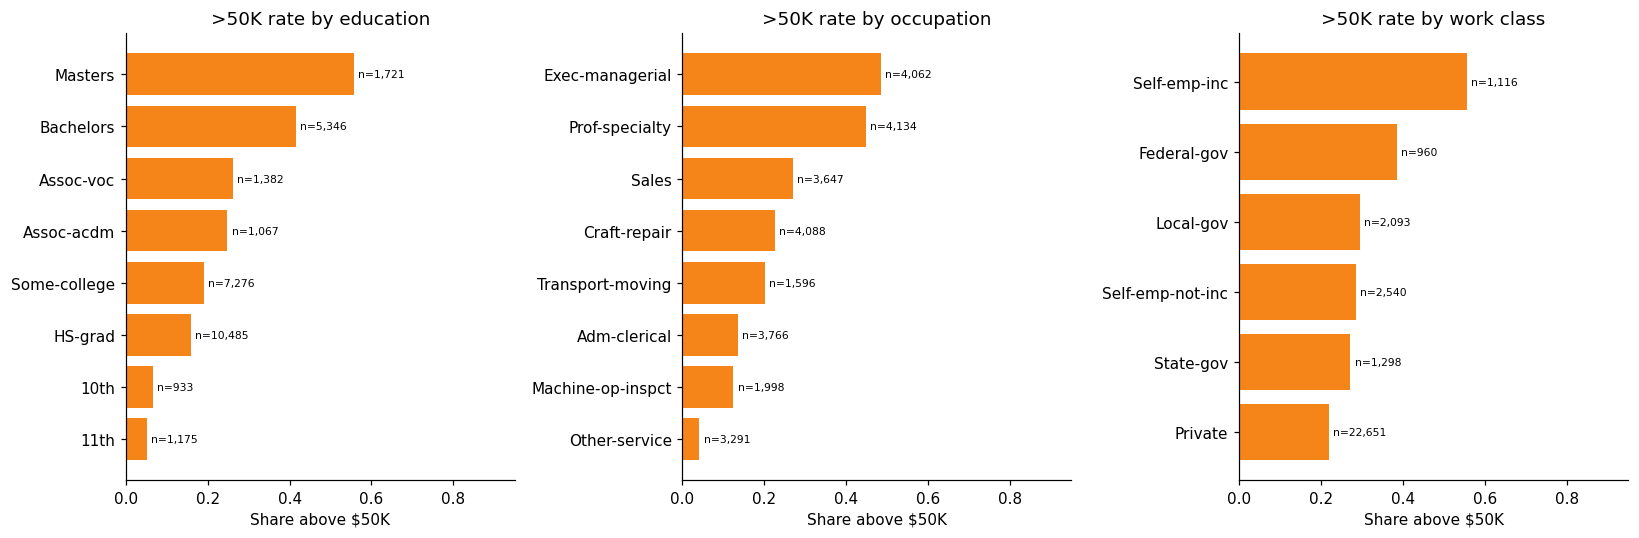

Rates differ by category, but the group sizes matter.
These patterns do not show what caused a person's income.


In [6]:
# Compare the >50K rate across common categories.
features_to_plot = [
    "education",
    "occupation",
    "work_class"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, feature in zip(axes, features_to_plot):
    number_of_categories = 6 if feature == "work_class" else 8
    common = development[feature].value_counts().head(number_of_categories).index

    subset = development.loc[
        development[feature].isin(common)
    ].copy()
    subset["above_50k"] = subset["income"].eq(">50K")

    summary = subset.groupby(feature).agg(
        rate=("above_50k", "mean"),
        count=("above_50k", "size")
    )
    summary = summary.sort_values("rate")

    bars = ax.barh(summary.index, summary["rate"], color="#F58518")

    for bar, count in zip(bars, summary["count"]):
        ax.text(
            bar.get_width() + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"n={count:,}",
            va="center",
            fontsize=7
        )

    ax.set(
        title=f">50K rate by {feature.replace('_', ' ')}",
        xlabel="Share above $50K",
        xlim=(0, 0.95)
    )

plt.tight_layout()
plt.show()

print("Rates differ by category, but the group sizes matter.")
print("These patterns do not show what caused a person's income.")


## 3. Prepare features and compare models

I checked that `education_num` is a numeric code for the same education information in `education`. I keep `education` and drop `education_num` so the information is not counted twice. I retain `fnlwgt` as an input feature, but I do not treat it as the person's income or use it to weight the model.

For categorical columns, I fill unknown values using the most common training-fold category and then one-hot encode them. For numeric columns, I use median imputation. Logistic Regression also gets scaled numeric values. I put all of these steps **inside each pipeline**; fitting an encoder on the full dataset before cross-validation would let information from validation folds leak into training.

### How I choose a model

I use the same **three stratified folds** for every model. Before looking at the test results, I choose **F1 for the `>50K` class** as the selection metric. That makes sense here because I care about finding positive records without calling too many negative records positive. The model settings are small, deliberate examples rather than an exhaustive tuning search.


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# education_num repeats the information in education.
education_mapping = development.groupby("education")["education_num"].nunique()
assert education_mapping.max() == 1

FEATURES = [
    col for col in COLUMNS
    if col not in ["income", "education_num"]
]

X_dev = development[FEATURES]
y_dev = development["income"].eq(">50K").astype(int)

X_test = holdout[FEATURES]
y_test = holdout["income"].eq(">50K").astype(int)

categorical = X_dev.select_dtypes(include="object").columns.tolist()
numeric = X_dev.select_dtypes(exclude="object").columns.tolist()


def make_preprocessor(scale_numeric=False):
    # Learn missing values and category levels from each training fold.
    categorical_steps = [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]

    numeric_steps = [
        ("impute", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))

    preprocessor = ColumnTransformer([
        ("cat", Pipeline(categorical_steps), categorical),
        ("num", Pipeline(numeric_steps), numeric)
    ])

    return preprocessor


# Create each model with its own preprocessing pipeline.
dummy_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", DummyClassifier(strategy="most_frequent"))
])

log_model = Pipeline([
    ("prep", make_preprocessor(scale_numeric=True)),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=SEED
    ))
])

tree_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=9,
        random_state=SEED
    ))
])

base_tree = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=9
)
bagging_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", BaggingClassifier(
        estimator=base_tree,
        n_estimators=40,
        random_state=SEED,
        n_jobs=1
    ))
])

rf_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=80,
        min_samples_leaf=3,
        random_state=SEED,
        n_jobs=1
    ))
])

gb_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", GradientBoostingClassifier(
        n_estimators=60,
        max_depth=2,
        learning_rate=0.1,
        random_state=SEED
    ))
])

xgb_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", XGBClassifier(
        n_estimators=80,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=1
    ))
])

models = {
    "Majority baseline": dummy_model,
    "Logistic Regression": log_model,
    "Decision Tree": tree_model,
    "Bagging": bagging_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

print(f"Development rows: {len(X_dev):,}")
print(f"Test rows: {len(X_test):,}")
print("Categorical columns:", categorical)
print("Numeric columns:", numeric)
print("Dropped education_num because it repeats education.")


Development rows: 32,511
Test rows: 16,281
Categorical columns: ['work_class', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Numeric columns: ['age', 'fnlwgt', 'capital_gain', 'capital_loss', 'hours_per_week']
Dropped education_num because it repeats education.


### What each model adds

| Model | Why I included it |
| --- | --- |
| Majority baseline | Shows what happens if I always choose the common class. |
| Logistic Regression | Gives me a simple linear reference point. |
| Decision Tree | Makes individual split rules easy to understand. |
| Bagging | Tests whether averaging bootstrapped trees helps. |
| Random Forest | Adds random feature selection to a collection of trees. |
| Gradient Boosting | Builds trees in sequence to improve earlier predictions. |
| XGBoost | Lets me compare another boosting implementation. |

The next cell reports each model's average validation F1 and its training-to-validation F1 gap. A large gap can be a sign that the model fits its training folds better than it generalizes. I select the model using **validation results only**.


In [8]:
# Use the same stratified folds for each model.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

cv_rows = []

for name, model in models.items():
    start_time = time.time()

    scores = cross_validate(
        model,
        X_dev,
        y_dev,
        cv=cv,
        scoring={
            "f1": "f1",
            "acc": "accuracy"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    cv_f1 = scores["test_f1"].mean()
    train_f1 = scores["train_f1"].mean()

    row = {
        "model": name,
        "cv_f1": cv_f1,
        "cv_f1_sd": scores["test_f1"].std(),
        "cv_accuracy": scores["test_acc"].mean(),
        "train_f1": train_f1,
        "train_cv_gap": train_f1 - cv_f1
    }
    cv_rows.append(row)

    elapsed = time.time() - start_time
    print(
        f"{name}: CV F1 = {cv_f1:.3f} ± {row['cv_f1_sd']:.3f}; "
        f"train-CV gap = {row['train_cv_gap']:.3f}; "
        f"time = {elapsed:.1f}s"
    )

cv_results = pd.DataFrame(cv_rows)
cv_results = cv_results.sort_values("cv_f1", ascending=False).reset_index(drop=True)

selected_name = cv_results.loc[0, "model"]
print("\nSelected from development CV:", selected_name)


Majority baseline: CV F1 = 0.000 ± 0.000; train-CV gap = 0.000; time = 0.3s
Logistic Regression: CV F1 = 0.658 ± 0.005; train-CV gap = 0.005; time = 0.5s
Decision Tree: CV F1 = 0.660 ± 0.009; train-CV gap = 0.025; time = 0.5s
Bagging: CV F1 = 0.662 ± 0.008; train-CV gap = 0.024; time = 6.9s
Random Forest: CV F1 = 0.682 ± 0.004; train-CV gap = 0.062; time = 5.3s
Gradient Boosting: CV F1 = 0.626 ± 0.007; train-CV gap = 0.006; time = 2.4s
XGBoost: CV F1 = 0.661 ± 0.006; train-CV gap = 0.008; time = 0.5s

Selected from development CV: Random Forest


## 4. Test the finished models

The model choice is already fixed by cross-validation. I now fit each complete pipeline on all development rows and apply it to the same, untouched test file. The class predictions use the default probability cutoff of **0.5**.

| Measure | How I read it |
| --- | --- |
| Accuracy | Fraction of all records classified correctly. |
| Precision | Of the records predicted `>50K`, how many really are? |
| Recall | Of the records actually `>50K`, how many did the model find? |
| F1 | A balance between positive-class precision and recall. |
| ROC-AUC | How well the probabilities rank positive records above negative ones across cutoffs. |

I report both the development cross-validation scores and the final test scores. The test table helps me understand the models; it does **not** change which model I selected.


In [9]:
# Fit on development data, then evaluate on the same test set.
rows = []
fitted = {}
cv_lookup = cv_results.set_index("model")

for name, model in models.items():
    model.fit(X_dev, y_dev)
    fitted[name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    cv_row = cv_lookup.loc[name]

    row = {
        "model": name,
        "cv_f1": cv_row["cv_f1"],
        "cv_f1_sd": cv_row["cv_f1_sd"],
        "train_cv_gap": cv_row["train_cv_gap"],
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_precision": precision_score(y_test, predictions, zero_division=0),
        "test_recall": recall_score(y_test, predictions, zero_division=0),
        "test_f1": f1_score(y_test, predictions, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, probabilities)
    }
    rows.append(row)

results = pd.DataFrame(rows)
results = results.sort_values("cv_f1", ascending=False).reset_index(drop=True)

positive_count = int(y_test.sum())
positive_share = y_test.mean()

print(f"Test rows: {len(y_test):,}")
print(f">50K rows: {positive_count:,} ({positive_share:.1%})")
print("\nModel comparison:\n")
print(results.round(3).to_string(index=False))


Test rows: 16,281
>50K rows: 3,846 (23.6%)

Model comparison:

              model  cv_f1  cv_f1_sd  train_cv_gap  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc
      Random Forest  0.682     0.004         0.062          0.865           0.772        0.611    0.682         0.914
            Bagging  0.662     0.008         0.024          0.863           0.789        0.576    0.666         0.910
            XGBoost  0.661     0.006         0.008          0.865           0.809        0.563    0.664         0.915
      Decision Tree  0.660     0.009         0.025          0.859           0.772        0.572    0.657         0.897
Logistic Regression  0.658     0.005         0.005          0.851           0.728        0.586    0.649         0.904
  Gradient Boosting  0.626     0.007         0.006          0.855           0.811        0.504    0.622         0.904
  Majority baseline  0.000     0.000         0.000          0.764           0.000        0.000    0.000        

### What I notice in the cross-validation results

- **`cv_f1`** is the average validation F1 across the three folds. Random Forest is highest at **0.682**; Bagging is next at **0.662**. I selected Random Forest using this result, before looking at the test set.
- **`cv_f1_sd`** is the standard deviation of those three validation scores. Random Forest's value is **0.004**, so its scores were close across these folds. Three folds are still too few to treat that number as a guarantee of future performance.
- **`train_cv_gap`** is average training F1 minus average validation F1. Random Forest's gap is **0.062**, meaning it scored about **0.744** on its training folds versus **0.682** on validation folds. Its gap is larger than those of Logistic Regression (**0.005**) and Bagging (**0.024**), which is a sign of greater overfitting risk in this comparison.

The majority baseline has F1 **0.000** because it never predicts the `>50K` class. The cross-validation results tell me which model to take forward; the separate test file gives the final check.

### 4.1 Compare test F1

This chart makes the differences in positive-class F1 easier to see. It is a final comparison, not another selection step: the selected model comes from development cross-validation.


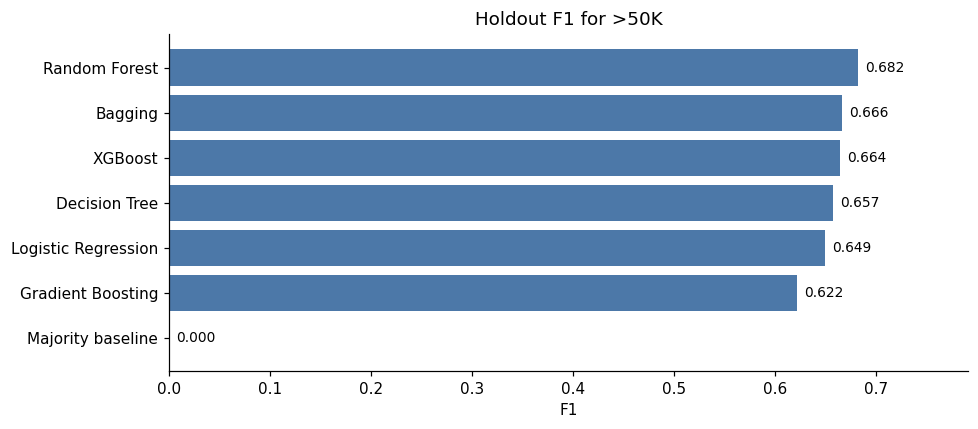

I selected the model using development CV, not this test chart.


In [10]:
# Plot the final F1 score for each model.
ordered = results.sort_values("test_f1")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(
    ordered["model"],
    ordered["test_f1"],
    color="#4C78A8"
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.007,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.3f}",
        va="center",
        fontsize=9
    )

ax.set(
    title="Holdout F1 for >50K",
    xlabel="F1",
    xlim=(0, max(0.1, ordered["test_f1"].max() * 1.16))
)

plt.tight_layout()
plt.show()

print("I selected the model using development CV, not this test chart.")


### 4.2 Look at the mistakes

I use a confusion matrix to see what the overall score hides. A **false negative** is a record that really is `>50K` but was predicted `<=50K`. A **false positive** is the opposite. The matrix rows are actual classes and its columns are predicted classes.


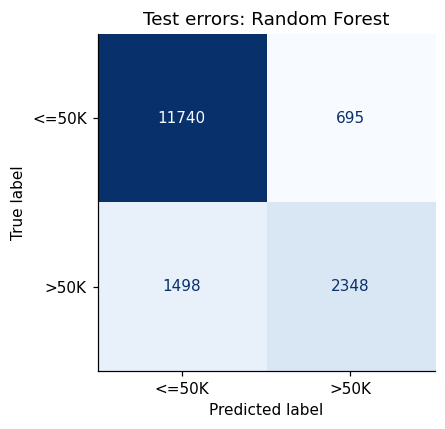

True negatives: 11,740
False positives: 695
False negatives: 1,498
True positives: 2,348


In [11]:
# Look at the kinds of errors made by the selected model.
selected_model = fitted[selected_name]
selected_pred = selected_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    selected_pred,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(5, 4))
display = ConfusionMatrixDisplay(
    cm,
    display_labels=["<=50K", ">50K"]
)
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)
ax.set_title(f"Test errors: {selected_name}")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn:,}")
print(f"False positives: {fp:,}")
print(f"False negatives: {fn:,}")
print(f"True positives: {tp:,}")


## 5. Look beyond the overall score

### 5.1 Errors across groups

I calculate error rates by the dataset's `sex` and `race` categories and show the size of each group. I did not use these numbers to pick the model. They are a first check, not a fairness assessment: overall error rates do not tell me whether a group has more missed positives or more false alarms. The same overall error rate can hide different precision and recall across groups.


In [12]:
# Check overall error rates across the dataset's group labels.
diagnostics = X_test[["sex", "race"]].copy()
diagnostics["actual"] = y_test.to_numpy()
diagnostics["predicted"] = selected_pred
diagnostics["error"] = diagnostics["actual"] != diagnostics["predicted"]

for feature in ["sex", "race"]:
    group = diagnostics.groupby(feature, dropna=False).agg(
        records=("error", "size"),
        errors=("error", "sum"),
        error_rate=("error", "mean")
    )
    group = group.sort_values("records", ascending=False)

    print(f"\nErrors by {feature}:\n")
    print(group.round(3).to_string())

print("\nThese rates describe this test sample; they do not establish fairness or cause.")



Errors by sex:

        records  errors  error_rate
sex                                
Male      10860    1818       0.167
Female     5421     375       0.069

Errors by race:

                    records  errors  error_rate
race                                           
White                 13946    1974       0.142
Black                  1561     116       0.074
Asian-Pac-Islander      480      75       0.156
Amer-Indian-Eskimo      159      13       0.082
Other                   135      15       0.111

These rates describe this test sample; they do not establish fairness or cause.


### 5.2 A few individual errors

I look at five misclassified records to get a feel for the kinds of mistakes the model makes. They are examples, not evidence that a particular feature caused the mistake or that the same pattern holds for everyone.


In [13]:
# Read a few errors without displaying every feature.
error_mask = selected_pred != y_test.to_numpy()
example_columns = [
    "age",
    "education",
    "occupation",
    "hours_per_week"
]

examples = X_test.loc[error_mask, example_columns].head(5).copy()
examples["actual_income"] = holdout.loc[examples.index, "income"].to_numpy()
examples["predicted_income"] = np.where(
    selected_pred[examples.index] == 1,
    ">50K",
    "<=50K"
)

print("Five example errors:")
print(examples.to_string(index=False))


Five example errors:
 age  education        occupation  hours_per_week actual_income predicted_income
  28 Assoc-acdm   Protective-serv              40          >50K            <=50K
  36  Bachelors      Adm-clerical              40         <=50K             >50K
  48    HS-grad Machine-op-inspct              48          >50K            <=50K
  28  Assoc-voc    Prof-specialty              36          >50K            <=50K
  46  Assoc-voc      Tech-support              40         <=50K             >50K


### 5.3 Which inputs matter to this model?

The following chart shows the selected model's highest-ranked encoded features. I use it to understand what the fitted model relied on, not to claim that these features cause income. Related features can split importance between them, and the ranking can change with another sample.



Top ten feature importances:
num__capital_gain                         0.149
cat__marital_status_Married-civ-spouse    0.119
cat__relationship_Husband                 0.106
num__age                                  0.086
num__hours_per_week                       0.055
num__capital_loss                         0.042
num__fnlwgt                               0.042
cat__marital_status_Never-married         0.038
cat__occupation_Exec-managerial           0.035
cat__education_Bachelors                  0.035


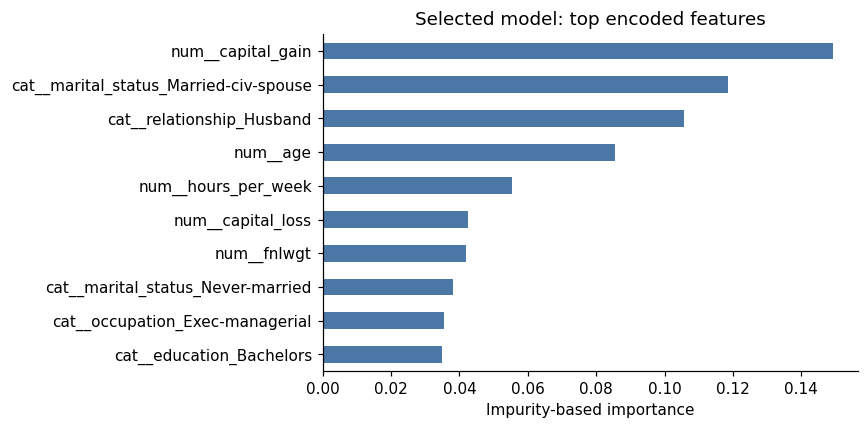

These values show model associations, not causes.


In [14]:
# Inspect what the selected model used most.
fitted_estimator = selected_model.named_steps["model"]
feature_names = selected_model.named_steps["prep"].get_feature_names_out()

if hasattr(fitted_estimator, "feature_importances_"):
    importance = pd.Series(
        fitted_estimator.feature_importances_,
        index=feature_names
    )
    importance = importance.sort_values(ascending=False).head(10)

    print("Top ten feature importances:")
    print(importance.round(3).to_string())

    fig, ax = plt.subplots(figsize=(8, 4))
    importance.sort_values().plot.barh(
        ax=ax,
        color="#4C78A8"
    )
    ax.set(
        title="Selected model: top encoded features",
        xlabel="Impurity-based importance"
    )

    plt.tight_layout()
    plt.show()

elif hasattr(fitted_estimator, "coef_"):
    coefficients = pd.Series(
        fitted_estimator.coef_[0],
        index=feature_names
    )
    top_features = coefficients.abs().sort_values(ascending=False).head(10).index

    print("Largest absolute coefficients:")
    print(coefficients.loc[top_features].round(3).to_string())

else:
    print("This model has no direct feature-importance attribute.")

print("These values show model associations, not causes.")


## 6. What I found

**Random Forest was my choice** because it had the highest average development cross-validation F1 for the `>50K` class: **0.682 ± 0.004** across three folds. Its test F1 was also **0.682**.

| Model | Development CV F1 | Test accuracy | Test precision | Test recall | Test F1 |
| --- | ---: | ---: | ---: | ---: | ---: |
| Majority baseline | 0.000 | 0.764 | 0.000 | 0.000 | 0.000 |
| Random Forest | **0.682** | **0.865** | 0.772 | **0.611** | **0.682** |
| XGBoost | 0.661 | **0.865** | **0.808** | 0.563 | 0.664 |

The baseline gets **76.4% accuracy** by always predicting `<=50K`, but it never finds someone in the `>50K` class. That is the clearest lesson from this comparison: accuracy alone makes this dataset look easier than it is. XGBoost has higher precision, while Random Forest has higher recall and F1. Their test accuracies and ROC-AUC scores are close.

### Where Random Forest still struggles

There are **3,846** `>50K` records in the test file. Random Forest finds **2,348** of them and misses **1,498**; it also makes **695** false-positive predictions. In other words, the model catches about **61%** of the positive records. The balance between missed positives and false alarms depends on the application. This project has no real-world cost assigned to either mistake.

Its average training F1 is **0.062** above its average validation F1, a larger gap than several simpler models. That gives me a reason to watch for overfitting. The differences between models are also fairly small, and three validation folds do not prove that this choice will win on every future sample.

This is a learning exercise using historical data with sensitive attributes. The group patterns and feature rankings are **associations, not causes**. I would not use this model to make employment or pay decisions.
